# CS 363M Final Project
Luke Henderson (ldh2674)  
Evan White
Akhil Jarabandi

## Introduction

Parkinson's disease is a progressive neurodegenerative disorder of the central nervous system that primarily affects movement. It affects approximately 1 million Americans, with common symptoms including tremors, stiffness, and slowed movement. Although there is no cure, medications and deep brain stimulation can manage symptoms. The disease is not typically directly fatal, but complications can be life-threatening. Early diagnosis allows for earlier treatment and improved quality of life.

Clinicians assess disease severity with the Unified Parkinson's Disease Rating Scale. Motor UPDRS measures motor symptoms, and total UPDRS measures overall severity, including motor and non-motor symptoms. Higher scores indicate more severe symptoms. This project predicts total UPDRS from voice measurements so that changes in disease severity can be monitored remotely.

## Dataset Description

The Parkinson's Telemonitoring Dataset contains 5,875 voice recordings from 42 patients with early-stage Parkinson's disease, collected over a six-month period. Developed by researchers at the University of Oxford in collaboration with 10 U.S. medical centers and Intel, the dataset explores how changes in speech can be used to monitor Parkinson's disease progression remotely.

Each recording contains 16 biomedical voice measurements, along with patient demographics, time since enrollment, Motor_UPDRS, and Total_UPDRS. The prediction target is total UPDRS. It is the broader severity score because it includes motor and non-motor symptoms. Motor UPDRS remains in the dataset for validity checks and is excluded from the predictors.

The features of the dataset are as follows: 
- Subject: Integer that uniquely identifies each subject  
- Age: Subject age  
- Sex: Subject gender ‘0’ - male, ‘1’ - female  
- Test_time: Time since recruitment into the trial. The integer part is the number of days since recruitment  
- Motor_UPDRS: Clinician’s motor UPDRS score, linearly interpolated  
- Total_UPDRS: Clinician’s total UPDRS score, linearly interpolated  
- Jitter (%), Jitter(Abs), Jitter. RAP, Jitter. PPQ5, Jitter. DDP: Several measures of variation in fundamental frequency (Frequency parameters)  
- Shimmer, Shimmer (dB), Shimmer. APQ3, Shimmer. APQ5, Shimmer. APQ11, Shimmer. DDA: Several measures of variation in amplitude (Amplitude parameters)  
- NHR, HNR: Two measures of ratio of noise to tonal components in the voice  
- RPDE: A nonlinear dynamical complexity measure  
- DFA: Signal fractal scaling exponent  
- PPE: A nonlinear measure of fundamental frequency variation  
  
These voice measurements capture variations in pitch, loudness, noise, and vocal stability, which can be affected by Parkinson's disease. By analyzing patterns in these features, we aim to develop models that accurately predict total UPDRS and support noninvasive, remote monitoring of disease severity and progression.

## Data Prep

### Check for missing, infinite, duplicate, and repeated values

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/parkinsons_updrs.csv")
repeated_patient_times = df.duplicated(subset=["subject#", "test_time"])

# Check for missing values, infinities, and duplicate rows
print("Missing values:", df.isna().sum().sum())
print("Infinite values:", np.isinf(df).sum().sum())
print(f"Repeated patient/time pairs: {repeated_patient_times.sum():,}")     # multiple recordings that have the same patient and record time as another row (expected, not a problem)
print("Duplicate rows:", df.duplicated().sum())

df.head()

Missing values: 0
Infinite values: 0
Repeated patient/time pairs: 3,374
Duplicate rows: 0


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


The dataset contains no missing values, infinite values, or exact duplicate rows, so no cleaning was necessary. There are 3,374 repeated patient/time pairs, which is expected since patients can have multiple voice recordings at the same recorded time.

### Invalid values check

In [2]:
# Check for invalid or inconsistent values
print("Invalid ages:", ((df["age"] <= 0) | (df["age"] > 120)).sum())
print("Invalid sex values:", (~df["sex"].isin([0, 1])).sum())

print("Negative UPDRS scores:",
      ((df["motor_UPDRS"] < 0) | (df["total_UPDRS"] < 0)).sum())

print("Total UPDRS below motor UPDRS:",
      (df["total_UPDRS"] < df["motor_UPDRS"]).sum())

print("Negative test times:", (df["test_time"] < 0).sum())

Invalid ages: 0
Invalid sex values: 0
Negative UPDRS scores: 0
Total UPDRS below motor UPDRS: 0
Negative test times: 12



All ages, sex values, and UPDRS scores passed the validity checks. There were 12 recordings with negative test times, which may represent measurements taken before the enrollment reference date. Since these are not necessarily errors, we decided to keep them.

### Inspect outliers

In [3]:
continuous = df.drop(columns=["subject#", "sex"])

# Uses Tukeys Fences to detect outliers
q1 = continuous.quantile(0.25)
q3 = continuous.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_flags = (continuous < lower) | (continuous > upper)

outlier_counts = outlier_flags.sum()
outlier_report = pd.DataFrame({
    "lower_fence": lower,
    "upper_fence": upper,
    "outlier_count": outlier_counts,
    "outlier_percent": (outlier_flags.mean() * 100).round(2),
}).sort_values("outlier_count", ascending=False)

display(outlier_report)
print(f"Rows with at least one outlier: {outlier_flags.any(axis=1).sum():,} (all retained)")

,lower_fence,upper_fence,outlier_count,outlier_percent
NHR,-0.019807,0.062225,436,7.42
Jitter:PPQ5,-0.000640,0.005920,425,7.23
Jitter:RAP,-0.000985,0.005855,414,7.05
Jitter:DDP,-0.002980,0.017580,413,7.03
Jitter(%),-0.001250,0.011630,398,6.77
Jitter(Abs),-0.000024,0.000100,366,6.23
Shimmer,-0.011825,0.070695,333,5.67
Shimmer(dB),-0.110000,0.650000,332,5.65
Shimmer:APQ3,-0.007663,0.037518,332,5.65
Shimmer:DDA,-0.023027,0.112592,331,5.63


Rows with at least one outlier: 931 (all retained)


Using Tukey's fences (1.5 × IQR), 931 recordings were flagged as having at least one outlier. Most outliers occurred in the NHR, Jitter, and Shimmer measurements, with roughly 5–7% of values flagged for several of these features. Since extreme voice measurements could reflect genuine differences in Parkinson's symptoms, I decided not to remove any observations.

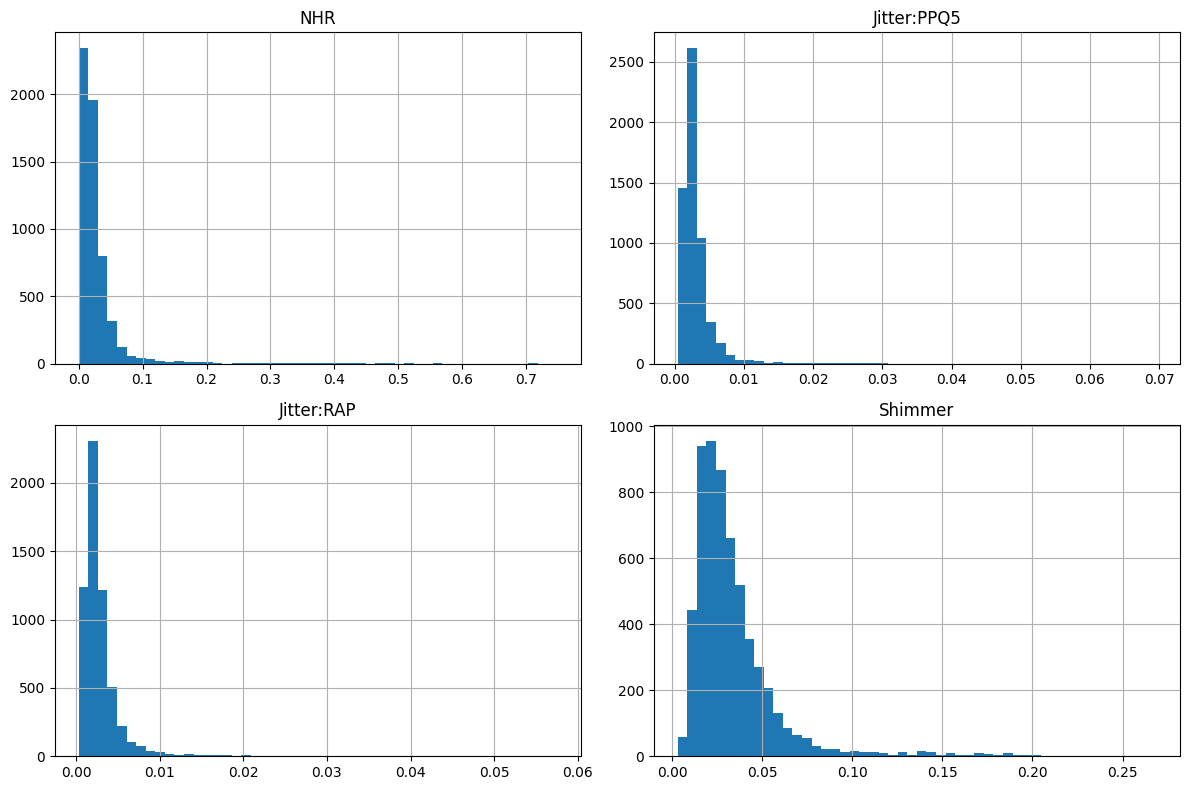

In [4]:
import matplotlib.pyplot as plt

features = ["NHR", "Jitter:PPQ5", "Jitter:RAP", "Shimmer"]

df[features].hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

The histograms show that NHR, Jitter, and Shimmer are strongly right-skewed, with most measurements concentrated at lower values and a relatively small number extending much higher. This explains why the IQR method identified so many outliers. The extreme values appear to be part of long-tailed distributions rather than obvious data errors, so I will retain them for modeling and consider transformations if needed.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(splitter.split(df, groups=df["subject#"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Training recordings:", len(train))
print("Testing recordings:", len(test))
print("Training patients:", train["subject#"].nunique())
print("Testing patients:", test["subject#"].nunique())

Training recordings: 4640
Testing recordings: 1235
Training patients: 33
Testing patients: 9


## Data Exploration

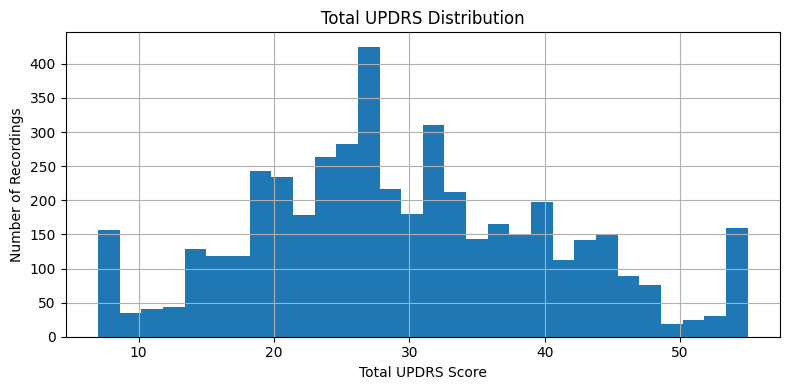

,total_UPDRS
count,4640.000000
mean,29.565597
std,11.022521
min,7.000000
25%,21.715000
50%,28.115500
75%,37.236250
max,54.992000


In [6]:
import matplotlib.pyplot as plt

target = "total_UPDRS"

ax = train[[target]].hist(bins=30, figsize=(8, 4)).flat[0]
ax.set_title("Total UPDRS Distribution")
ax.set_xlabel("Total UPDRS Score")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

display(train[[target]].describe())

The training set contains 4,640 recordings. Total UPDRS ranges from 7.00 to 54.99 and is concentrated around scores of 20–35. The distribution is not strongly skewed, although it has several peaks, which may reflect differences in disease severity between patients. Because the target already covers a broad range of scores, I don't see an immediate need to transform it.

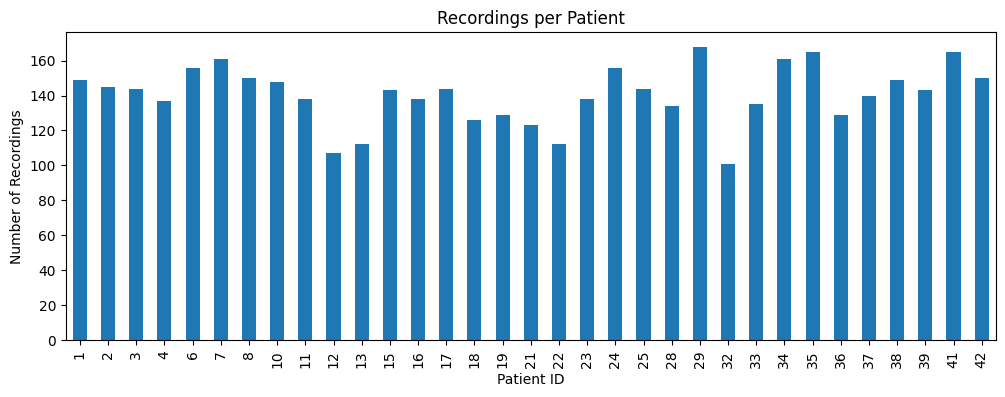

count     33.000000
mean     140.606061
std       16.695694
min      101.000000
25%      134.000000
50%      143.000000
75%      150.000000
max      168.000000
dtype: float64

In [7]:
recordings = train.groupby("subject#").size()

recordings.plot(kind="bar", figsize=(12, 4))
plt.title("Recordings per Patient")
plt.xlabel("Patient ID")
plt.ylabel("Number of Recordings")
plt.show()

display(recordings.describe())

Recording counts range from 101 to 168 and are relatively consistent across patients. Since no patient contributes substantially more recordings than the others, we do not see a need to rebalance or weight the observations by patient.

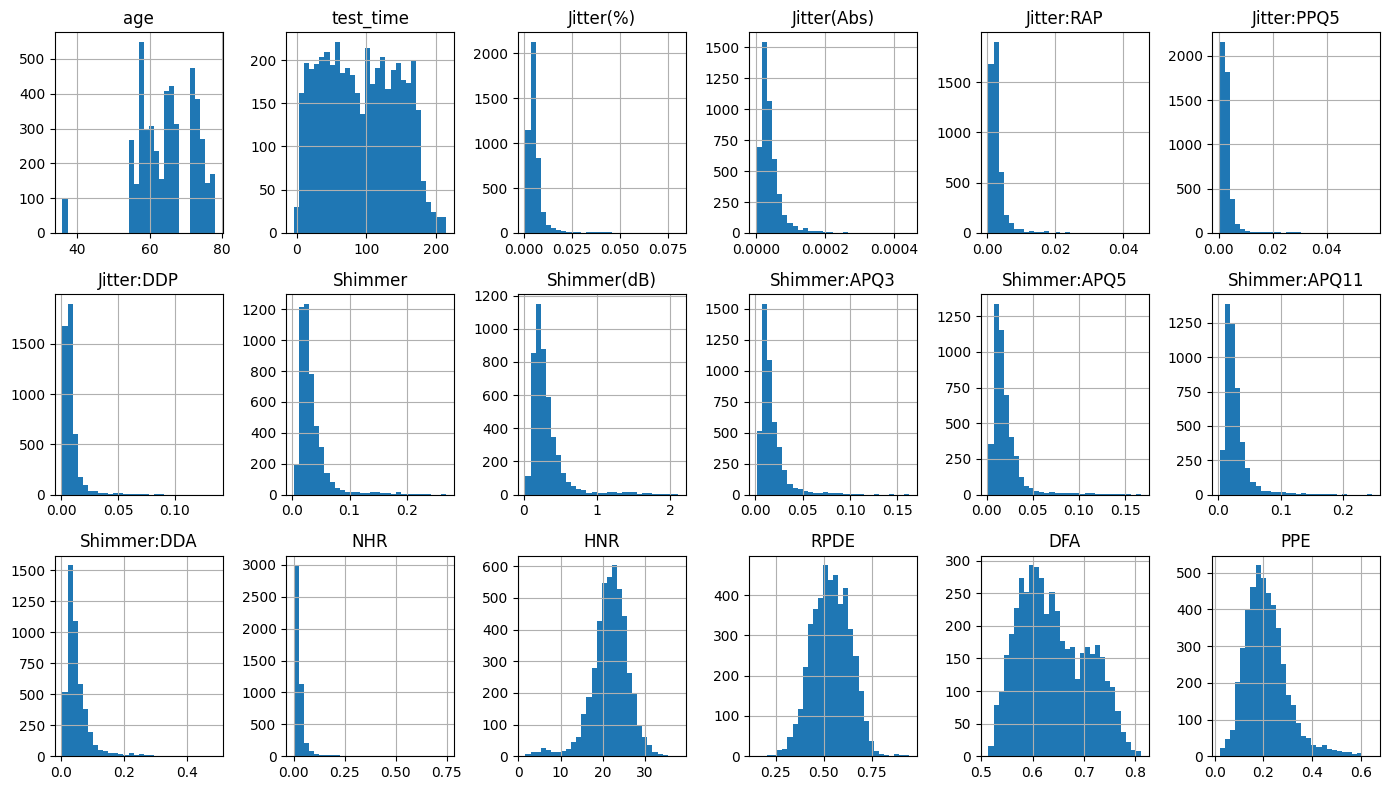

Jitter:PPQ5      6.492170
NHR              6.125149
Jitter:DDP       5.551170
Jitter:RAP       5.551042
Jitter(%)        5.264114
Shimmer:APQ5     3.822463
Jitter(Abs)      3.475975
Shimmer:APQ11    3.434173
Shimmer          3.397594
Shimmer:APQ3     3.205556
Shimmer:DDA      3.205552
Shimmer(dB)      3.181388
PPE              1.102557
DFA              0.330821
test_time        0.086193
RPDE             0.012532
age             -0.781646
HNR             -0.875499
dtype: float64

In [8]:
features = train.drop(
    columns=["subject#", "sex", "motor_UPDRS", "total_UPDRS"]
).columns

train[features].hist(bins=30, figsize=(14, 8), layout=(3, 6))
plt.tight_layout()
plt.show()

display(train[features].skew().sort_values(ascending=False))

Most of the jitter and shimmer measurements, along with NHR, are strongly right-skewed, while HNR and RPDE have more symmetric distributions. The features also vary considerably in scale so we will consider log transformations for highly skewed features and standardization for models sensitive to feature scale such as KNN.

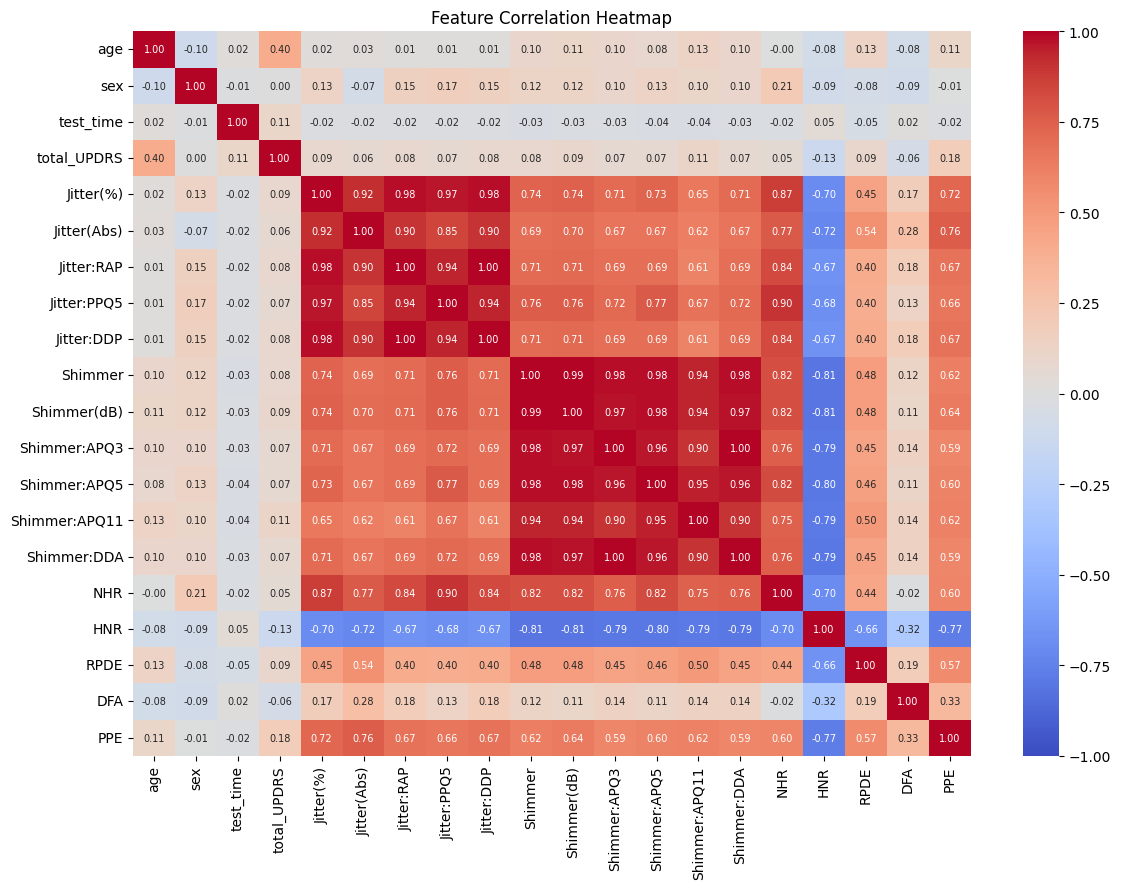

Jitter(%) & Jitter(Abs): 0.9189
Jitter(%) & Jitter:RAP: 0.9843
Jitter(%) & Jitter:PPQ5: 0.9675
Jitter(%) & Jitter:DDP: 0.9843
Jitter(Abs) & Jitter:RAP: 0.9039
Jitter(Abs) & Jitter:DDP: 0.9039
Jitter:RAP & Jitter:PPQ5: 0.9420
Jitter:RAP & Jitter:DDP: 1.0000
Jitter:PPQ5 & Jitter:DDP: 0.9420
Jitter:PPQ5 & NHR: 0.9026
Shimmer & Shimmer(dB): 0.9934
Shimmer & Shimmer:APQ3: 0.9812
Shimmer & Shimmer:APQ5: 0.9841
Shimmer & Shimmer:APQ11: 0.9442
Shimmer & Shimmer:DDA: 0.9812
Shimmer(dB) & Shimmer:APQ3: 0.9711
Shimmer(dB) & Shimmer:APQ5: 0.9768
Shimmer(dB) & Shimmer:APQ11: 0.9450
Shimmer(dB) & Shimmer:DDA: 0.9711
Shimmer:APQ3 & Shimmer:APQ5: 0.9631
Shimmer:APQ3 & Shimmer:APQ11: 0.9024
Shimmer:APQ3 & Shimmer:DDA: 1.0000
Shimmer:APQ5 & Shimmer:APQ11: 0.9478
Shimmer:APQ5 & Shimmer:DDA: 0.9631
Shimmer:APQ11 & Shimmer:DDA: 0.9024


In [9]:
import seaborn as sns

correlation = train.drop(columns=["subject#", "motor_UPDRS"]).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


feature_corr = train[features].corr()

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        corr = feature_corr.iloc[i, j]

        if abs(corr) >= 0.9:
            print(f"{features[i]} & {features[j]}: {corr:.4f}")

Most of the Jitter measurements are highly correlated with each other, and the same is true for Shimmer. We could combine these measurements into one feature for Jitter and one for Shimmer instead of using each measurement individually. Age has the strongest correlation with total UPDRS. Since the voice measurements have weak linear correlations with the target, we also want to test nonlinear models such as decision trees, neural nets, and KNN.

In [10]:
target_corr = correlation.loc[features, "total_UPDRS"]

display(target_corr.sort_values(key=abs, ascending=False))

age              0.401549
PPE              0.182730
HNR             -0.128897
Shimmer:APQ11    0.110255
test_time        0.105407
RPDE             0.089096
Shimmer(dB)      0.086736
Jitter(%)        0.085094
Jitter:DDP       0.079721
Jitter:RAP       0.079706
Shimmer          0.078839
Shimmer:APQ5     0.069368
Jitter:PPQ5      0.067484
Shimmer:DDA      0.065429
Shimmer:APQ3     0.065426
Jitter(Abs)      0.064836
DFA             -0.064137
NHR              0.048002
Name: total_UPDRS, dtype: float64

Age has the strongest correlation with total UPDRS, followed by PPE. Most of the other features have correlations below 0.1 in magnitude. Since no individual feature has a strong linear relationship with the target, we are going to see how well these features work together and whether nonlinear models perform better.

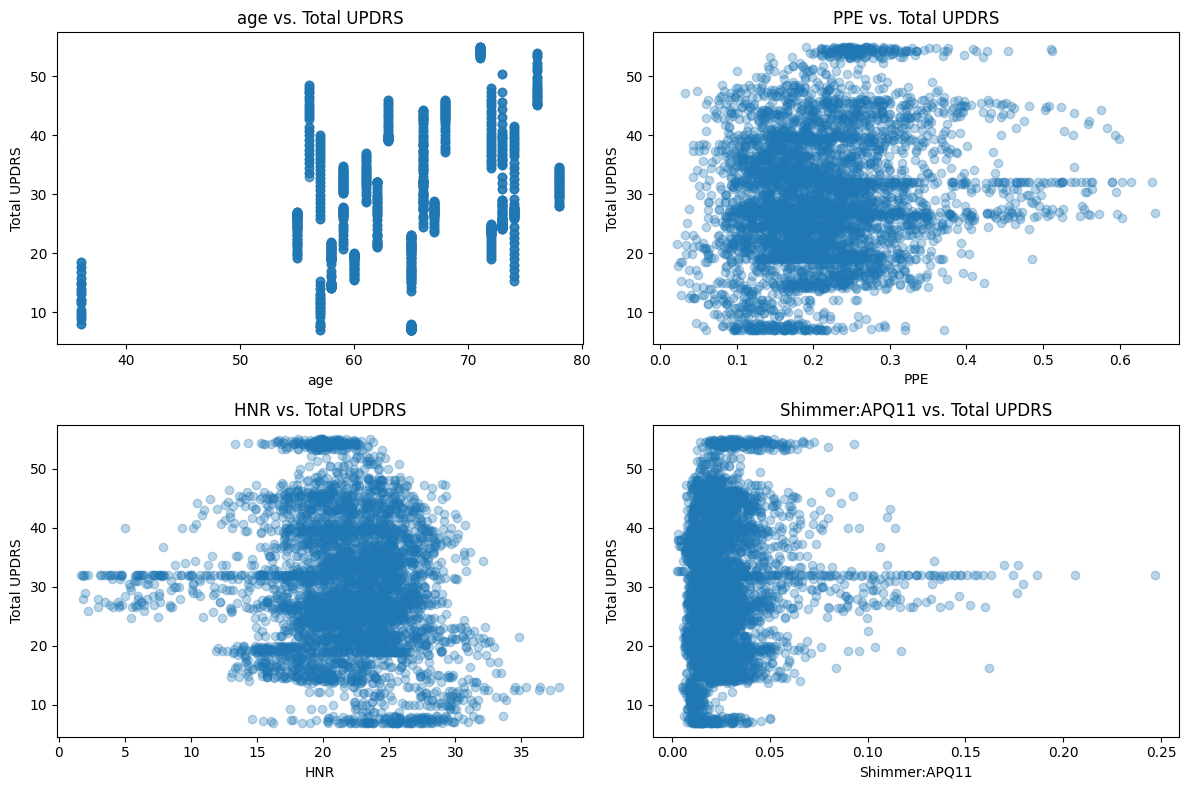

In [11]:
selected = target_corr.abs().nlargest(4).index

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected, axes.flat):
    ax.scatter(train[feature], train["total_UPDRS"], alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel("Total UPDRS")
    ax.set_title(f"{feature} vs. Total UPDRS")

plt.tight_layout()
plt.show()

Age shows the clearest relationship with total UPDRS, with older patients generally having higher scores. The other three features are much more scattered and do not show clear linear trends. This makes it difficult to predict UPDRS from any single voice measurement, so again, this leads us to test how well the features work together in both linear and nonlinear models.

### Compare log transformations

The Jitter, Shimmer, and NHR measurements were strongly right-skewed during exploration. We originally attempted to transform these features with a `log1p(x)` method, but found that it barely reduced skew. We then tested the natural log `log(x)` which effectively reduced the skew of the features. We compare their training-set skewness before transformation and after each transformation where values closer to zero indicate less skew.

In [12]:
X_train_raw = train.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"]).copy()
X_test_raw = test.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"]).copy()
y_train = train["total_UPDRS"].copy()
y_test = test["total_UPDRS"].copy()

jitter_cols = [col for col in X_train_raw if col.startswith("Jitter")]
shimmer_cols = [col for col in X_train_raw if col.startswith("Shimmer")]
log_cols = jitter_cols + shimmer_cols + ["NHR"]

if (X_train_raw[log_cols] <= 0).any().any():
    raise ValueError("Natural logs require strictly positive measurements.")

# Compare both methods on the same training measurements.
X_train_log1p = X_train_raw.copy()
X_train_log1p[log_cols] = np.log1p(X_train_raw[log_cols])
X_train_log = X_train_raw.copy()
X_train_log[log_cols] = np.log(X_train_raw[log_cols])

skew_comparison = pd.DataFrame({
    "Original": X_train_raw[log_cols].skew(),
    "Our first method: log1p(x)": X_train_log1p[log_cols].skew(),
    "Natural log: log(x)": X_train_log[log_cols].skew(),
})
skew_comparison.index.name = "Feature"
display(skew_comparison.round(3))

,Original,Our first method: log1p(x),Natural log: log(x)
Feature,,,
Jitter(%),5.264,5.156,0.936
Jitter(Abs),3.476,3.475,0.151
Jitter:RAP,5.551,5.477,0.845
Jitter:PPQ5,6.492,6.412,1.186
Jitter:DDP,5.551,5.340,0.845
Shimmer,3.398,3.194,0.592
Shimmer(dB),3.181,2.238,0.563
Shimmer:APQ3,3.206,3.076,0.390
Shimmer:APQ5,3.822,3.657,0.555


We chose the natural log because it reduced skewness much more than `log1p` for these small positive measurements—for example, NHR skewness fell from 6.13 to 0.39 with `log`, compared with 5.45 with `log1p`.

## Feature Engineering

In [13]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def log_voice(X):
    X = X.copy()
    if (X[log_cols] <= 0).any().any():
        raise ValueError("Natural logs require strictly positive measurements.")
    X[log_cols] = np.log(X[log_cols])
    return X

### Combine Jitter and Shimmer

Our earlier correlation analysis showed that the Jitter measurements are highly correlated with one another, as are the Shimmer measurements To reduce the dimensionality of our data we standardize and average the measurements within each group to create `Jitter_combined` and `Shimmer_combined` features, then remove the individual measurements.

In [14]:
def combine_voice(X):
    # The pipeline standardizes each measurement before we average its group.
    result = X.drop(columns=jitter_cols + shimmer_cols).copy()
    result["Jitter_combined"] = X[jitter_cols].mean(axis=1)
    result["Shimmer_combined"] = X[shimmer_cols].mean(axis=1)
    return result

### Changes from the first recording session

A patient’s voice may have changed even if their Jitter and Shimmer values look normal compared with other patients. To capture this, we subtract their first session’s values from each session’s values, averaging recordings taken at the same time. Positive values show an increase, negative values show a decrease, and the first session has zero change.

This requires the patient’s first session to be available for comparison. We only use voice measurements to calculate these changes, not UPDRS scores. They show how the voice has changed so far, not how it will change in the future.

In [15]:
def add_baseline_changes(X):
    features = ["Jitter_combined", "Shimmer_combined"]
    ordered = X.sort_values("test_time")
    current = ordered.groupby(["subject#", "test_time"])[features].transform("mean")
    baseline = current.groupby(ordered["subject#"]).transform("first")
    changes = current - baseline

    result = X.drop(columns="subject#").copy()
    for feature in features:
        result[feature + "_change"] = changes[feature].reindex(X.index)
    return result

In [16]:
# Create a fresh preprocessing pipeline for each feature option.
def feature_steps(version="combined"):
    if version not in ["raw", "logged", "combined", "demographics", "temporal"]:
        raise ValueError(f"Unknown feature option: {version}")

    log = FunctionTransformer(log_voice) if version in ["logged", "combined", "temporal"] else "passthrough"
    columns = ColumnTransformer([("raw", "passthrough", list(X_train_raw))])
    combine, changes = "passthrough", "passthrough"

    if version in ["combined", "temporal"]:
        other = [c for c in X_train_raw if c not in jitter_cols + shimmer_cols]
        if version == "temporal":
            other += ["subject#"]
            changes = FunctionTransformer(add_baseline_changes)
        columns = ColumnTransformer([
            ("other", "passthrough", other),
            ("jitter", StandardScaler(), jitter_cols),
            ("shimmer", StandardScaler(), shimmer_cols),
        ])
        combine = FunctionTransformer(combine_voice)
    elif version == "demographics":
        columns = ColumnTransformer([
            ("demographics", "passthrough", ["age", "sex", "test_time"])
        ])

    columns.set_params(verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([
        ("log", log), ("columns", columns),
        ("combine", combine), ("changes", changes),
    ])

We used the log transformation to reduce skew and combined Jitter and Shimmer because the measurements within each group were highly correlated. We compare these features with the original features and demographics alone to see whether the changes actually help prediction. All of the features are fitted using only the training patients in each CV fold.

### Final features before modeling

This preview lets us check the features before modeling. We reuse the same preprocessing functions in cross-validation, but fit the scalers separately within each training fold to prevent leakage.

In [17]:
X_train_inputs = X_train_raw.join(train["subject#"])
X_test_inputs = X_test_raw.join(test["subject#"])

preview = feature_steps("temporal")
X_train_temporal = preview.fit_transform(X_train_inputs)
X_test_temporal = preview.transform(X_test_inputs)

change_cols = ["Jitter_combined_change", "Shimmer_combined_change"]
X_train_reduced = X_train_temporal.drop(columns=change_cols)
X_test_reduced = X_test_temporal.drop(columns=change_cols)
groups_train = train.loc[X_train_temporal.index, "subject#"].copy()
groups_test = test.loc[X_test_temporal.index, "subject#"].copy()

assert set(groups_train).isdisjoint(groups_test)
assert X_train_temporal.index.equals(y_train.index)
assert X_test_temporal.index.equals(y_test.index)
assert X_train_temporal.columns.equals(X_test_temporal.columns)
assert np.isfinite(X_train_temporal.to_numpy()).all()
assert np.isfinite(X_test_temporal.to_numpy()).all()

print("Training features (including temporal):", X_train_temporal.shape)
print("Test features (including temporal):", X_test_temporal.shape)
patient = groups_train.iloc[0]
with pd.option_context("display.max_columns", None):
    display(X_train_temporal.loc[groups_train.eq(patient)].sort_values("test_time").head(10))


Training features (including temporal): (4640, 12)
Test features (including temporal): (1235, 12)


,age,sex,test_time,NHR,HNR,RPDE,DFA,PPE,Jitter_combined,Shimmer_combined,Jitter_combined_change,Shimmer_combined_change
0,72,0,5.6431,-4.248195,21.640,0.41888,0.54842,0.160060,0.545527,-0.205583,0.000000,0.000000
24,72,0,5.6431,-4.684430,27.927,0.37340,0.52499,0.170660,-0.992143,-1.768785,0.000000,0.000000
49,72,0,5.6438,-3.480565,26.641,0.50911,0.53637,0.251830,-0.549331,-1.416791,-0.326023,-0.429607
74,72,0,5.6451,-5.393288,30.749,0.41216,0.54572,0.094704,-1.595007,-2.375850,-1.371699,-1.388666
124,72,0,5.6458,-5.566981,32.102,0.31053,0.52767,0.065937,-1.381725,-2.790587,-1.022575,-1.301448
99,72,0,5.6458,-4.205120,27.530,0.40986,0.53572,0.166350,-1.110040,-1.786678,-1.022575,-1.301448
1,72,0,12.6660,-4.499730,27.183,0.43493,0.56477,0.108100,-0.939698,-0.598572,-0.716390,0.388612
50,72,0,12.6670,-4.783101,29.956,0.37935,0.53211,0.101020,-1.290821,-2.410371,0.097661,-0.053960
25,72,0,12.6670,-2.947095,20.533,0.55096,0.55348,0.260940,1.039528,0.328082,0.097661,-0.053960
125,72,0,12.6690,-4.280987,27.944,0.48257,0.52114,0.194580,-1.080537,-2.288397,-0.141916,-0.214400


## Modeling: Predicting total_UPDRS

In [18]:
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

folds = list(GroupKFold(5).split(X_train_raw, y_train, groups_train))
scores, model_specs = {}, {}
selected_parameters = {}
print("Training patients:", groups_train.nunique())
print("Outer validation folds:", len(folds))

Training patients: 33
Outer validation folds: 5


Each patient has many recordings, so splitting individual rows could let a model learn from the same patients it is evaluated on. We keep patients together and use the same five outer folds for every model. Three inner folds choose model settings using only the outer training patients, keeping the outer validation patients separate from tuning.

In [19]:
# evaluation loop
def evaluate(name, model, grid=None, version="combined", scale=True):
    pipe = Pipeline([
        ("features", feature_steps(version)),
        ("scale", StandardScaler() if scale else "passthrough"),
        ("model", model),
    ])
    model_specs[name] = (pipe, grid or {})
    rows = []
    selected_parameters[name] = []
    for fold, (a, b) in enumerate(folds, start=1):
        X_fit, X_val = X_train_inputs.iloc[a], X_train_inputs.iloc[b]
        y_fit, y_val = y_train.iloc[a], y_train.iloc[b]
        inner = list(GroupKFold(3).split(X_fit, y_fit, groups_train.iloc[a]))
        search = GridSearchCV(pipe, grid or {}, cv=inner,
                              scoring="neg_mean_absolute_error", error_score="raise")
        search.fit(X_fit, y_fit)
        for parameter, value in search.best_params_.items():
            selected_parameters[name].append({
                "Model": name, "Parameter": parameter.split("__")[-1],
                "Values tried": str(grid[parameter]),
                "Fold": fold, "Selected": str(value),
            })
        prediction = search.predict(X_val)
        rows.append({
            "Train MAE": mean_absolute_error(y_fit, search.predict(X_fit)),
            "CV MAE": mean_absolute_error(y_val, prediction),
            "CV RMSE": root_mean_squared_error(y_val, prediction),
            "CV R²": r2_score(y_val, prediction),
        })
    folds_table = pd.DataFrame(rows)
    scores[name] = folds_table.mean().to_dict()
    scores[name]["MAE fold SD"] = folds_table["CV MAE"].std()
    display(pd.DataFrame([scores[name]], index=[name]).round(3))

We use MAE as the main metric because it measures how many UPDRS points our predictions are off by, with RMSE highlighting larger errors and R² providing another performance measure. Comparing training and validation error helps us see whether a model fits known patients better than new ones. The fold standard deviation shows how much results change with the validation patients; it is not a confidence interval.

In [20]:
# Establish baselines and test our feature choices with linear regression.
evaluate("Mean baseline", DummyRegressor(), version="raw", scale=False)
evaluate("Median baseline", DummyRegressor(strategy="median"), version="raw", scale=False)

for version in ["raw", "logged", "combined", "demographics", "temporal"]:
    evaluate(f"Linear / {version}", LinearRegression(), version=version)

display(pd.DataFrame(scores).T.sort_values("CV MAE").round(3))

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Mean baseline,8.879,9.069,11.213,-0.24,1.602


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Median baseline,8.817,9.032,11.153,-0.24,1.644


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / raw,7.967,9.336,11.039,-0.222,1.833


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / logged,7.803,9.429,11.212,-0.252,1.892


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / combined,7.972,9.065,10.795,-0.146,1.976


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / demographics,8.334,8.728,10.432,-0.081,1.451


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / temporal,7.581,9.142,11.083,-0.218,1.574


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / demographics,8.334,8.728,10.432,-0.081,1.451
Median baseline,8.817,9.032,11.153,-0.240,1.644
Linear / combined,7.972,9.065,10.795,-0.146,1.976
Mean baseline,8.879,9.069,11.213,-0.240,1.602
Linear / temporal,7.581,9.142,11.083,-0.218,1.574
Linear / raw,7.967,9.336,11.039,-0.222,1.833
Linear / logged,7.803,9.429,11.212,-0.252,1.892


We start with constant predictions to check whether using the features helps at all. The median is a useful baseline because it minimizes absolute error on the training data. Since age had the strongest correlation with UPDRS, we also test demographics alone to see whether voice features add information beyond age, sex, and recording time.

The mean and median baselines had CV MAE 9.069 and 9.032. Logging alone increased linear regression's MAE from 9.336 to 9.429, while combining the logged measurements reduced it to 9.065. Demographics alone performed better at 8.728, so reducing skew and redundancy did not make the voice features more useful than demographics in this linear comparison.

We added changes from each patient’s first session to test whether changes in their voice were more useful than the measurements alone. Using the same regression model and validation patients lets us isolate what these two features contribute. Training MAE fell from 7.972 to 7.581, but validation MAE increased from 9.065 to 9.142. The extra features helped fit the training recordings without improving predictions for new patients.


In [21]:
# Test whether similar recordings have similar UPDRS scores.
evaluate("KNN", KNeighborsRegressor(), {
    "model__n_neighbors": [15, 50, 150],
    "model__weights": ["uniform", "distance"],
})

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
KNN,6.742,9.845,11.796,-0.355,2.4


Because the voice measurements had weak individual linear relationships with UPDRS, we test whether nearby recordings in feature space have similar scores using KNN. We vary the number of neighbors and their weighting to compare more local predictions with smoother ones, with scaling fitted inside each fold.

KNN had training MAE 6.742 but CV MAE 9.845, compared with 9.065 for combined-feature linear regression. Its closer fit to training recordings did not improve predictions for new patients.

In [22]:
# Compare a single tree with an ensemble of trees.
evaluate("Decision tree", DecisionTreeRegressor(random_state=42), {
    "model__max_depth": [2, 4, 8],
    "model__min_samples_leaf": [20, 100],
}, scale=False)

evaluate("Random forest", RandomForestRegressor(n_estimators=100, random_state=42), {
    "model__max_depth": [4, None],
    "model__min_samples_leaf": [20, 100],
}, scale=False)

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Decision tree,7.296,9.771,11.643,-0.394,2.616


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Random forest,5.407,10.758,12.619,-0.635,2.482


Decision trees can model thresholds and interactions that a linear model may miss. We limit depth and require larger leaves to reduce memorization, then average 100 trees in a random forest to test whether an ensemble generalizes better.

The tree had CV MAE 9.771 and the forest 10.758. Although the forest fit training data more closely (MAE 5.407 versus 7.296), it performed worse on validation patients, so averaging trees did not resolve the generalization problem in this experiment.

In [23]:
# Test nonlinear relationships with a small neural network.
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

neural_net = TransformedTargetRegressor(
    regressor=MLPRegressor(
        hidden_layer_sizes=(8,), activation="tanh", solver="lbfgs",
        alpha=1, max_iter=3000, max_fun=100000, random_state=42,
    ),
    transformer=StandardScaler(),
)
evaluate("Neural network", neural_net, {
    "model__regressor__hidden_layer_sizes": [(8,), (16,)],
    "model__regressor__alpha": [1, 100],
})

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Neural network,6.932,9.568,11.438,-0.28,2.218


Weak linear correlations do not rule out nonlinear relationships, so we test a neural network with a tanh activation function to possibly learn the non-linear relationships betwee the features and targets. We use one hidden layer with 8 or 16 neurons and compared two regularization strengths to limit complexity with only 33 training patients. Inputs and target scores are scaled within the training folds to help fitting, and predictions are converted back to UPDRS points before evaluation.

The network had training MAE 6.932 and CV MAE 9.568, compared with 9.065 for combined-feature linear regression. It fit the training data more closely but did not improve on combined-feature linear regression for new patients.

In [24]:
# Show what each inner search selected for its outer training fold.
tuning = pd.DataFrame([
    row for rows in selected_parameters.values() for row in rows
])
tuning_table = tuning.pivot(
    index=["Model", "Parameter", "Values tried"],
    columns="Fold", values="Selected",
).rename(columns=lambda fold: f"Fold {fold}")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tuning_table)

Fold                                                        Fold 1   Fold 2  \
Model          Parameter          Values tried                                
Decision tree  max_depth          [2, 4, 8]                      2        2   
               min_samples_leaf   [20, 100]                     20       20   
KNN            n_neighbors        [15, 50, 150]                150      150   
               weights            ['uniform', 'distance']  uniform  uniform   
Neural network alpha              [1, 100]                     100      100   
               hidden_layer_sizes [(8,), (16,)]              (16,)    (16,)   
Random forest  max_depth          [4, None]                      4        4   
               min_samples_leaf   [20, 100]                    100      100   

Fold                                                        Fold 3   Fold 4  \
Model          Parameter          Values tried                                
Decision tree  max_depth          [2, 4, 8]                      2        2   
               min_samples_leaf   [20, 100]                     20       20   
KNN            n_neighbors        [15, 50, 150]                150      150   
               weights            ['uniform', 'distance']  uniform  uniform   
Neural network alpha              [1, 100]                     100      100   
               hidden_layer_sizes [(8,), (16,)]               (8,)     (8,)   
Random forest  max_depth          [4, None]                      4        4   
               min_samples_leaf   [20, 100]                    100      100   

Fold                                                        Fold 5  
Model          Parameter          Values tried                      
Decision tree  max_depth          [2, 4, 8]                      2  
               min_samples_leaf   [20, 100]                     20  
KNN            n_neighbors        [15, 50, 150]                150  
               weights            ['uniform', 'distance']  uniform  
Neural network alpha              [1, 100]                     100  
               hidden_layer_sizes [(8,), (16,)]              (16,)  
Random forest  max_depth          [4, None]                   None  
               min_samples_leaf   [20, 100]                    100

We tuned these settings to see how much model complexity the data could support when predicting scores for new patients. The searches generally favored more averaging or stronger constraints, suggesting that limiting model flexibility helped more than fitting detailed patterns in the training recordings. This is consistent with having many recordings but only 33 training patients.

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / demographics,8.334,8.728,10.432,-0.081,1.451
Median baseline,8.817,9.032,11.153,-0.240,1.644
Linear / combined,7.972,9.065,10.795,-0.146,1.976
Mean baseline,8.879,9.069,11.213,-0.240,1.602
Linear / temporal,7.581,9.142,11.083,-0.218,1.574
Linear / raw,7.967,9.336,11.039,-0.222,1.833
Linear / logged,7.803,9.429,11.212,-0.252,1.892
Neural network,6.932,9.568,11.438,-0.280,2.218
Decision tree,7.296,9.771,11.643,-0.394,2.616
KNN,6.742,9.845,11.796,-0.355,2.400


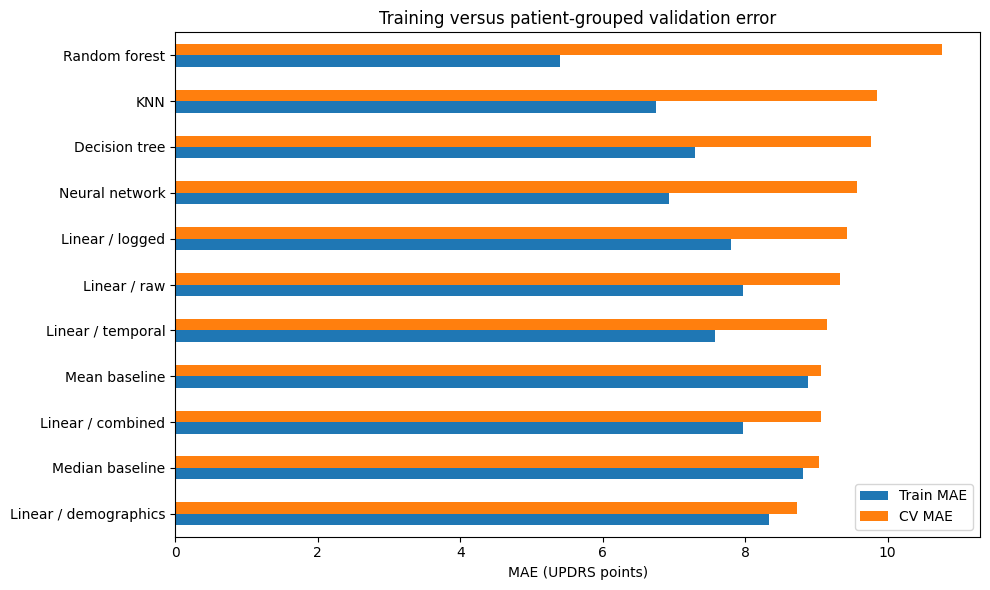

Selected by validation MAE: Linear / demographics


In [25]:
# Compare validation performance and training–validation gaps.
comparison = pd.DataFrame(scores).T.sort_values("CV MAE")
display(comparison.round(3))

comparison[["Train MAE", "CV MAE"]].plot.barh(figsize=(10, 6))
plt.xlabel("MAE (UPDRS points)")
plt.title("Training versus patient-grouped validation error")
plt.tight_layout()
plt.show()

winner = comparison.index[0]
print("Selected by validation MAE:", winner)

Linear regression using only age, sex, and recording time had the lowest CV MAE at 8.728, compared with 9.032 for the median baseline. This improvement was small relative to the variation across patient groups. Adding voice features did not improve validation performance in our experiments, even after logging and combining related measurements. The more complex models fit the training data better but had larger training–validation gaps, suggesting they learned patterns that did not carry over to new patients.

## Results & Analysis

In [26]:
# Compare demographics, combined voice, and temporal features on the test patients.
compared_models = ["Linear / demographics", "Linear / combined", "Linear / temporal"]
predictions = {}
for name in compared_models:
    model = clone(model_specs[name][0]).fit(X_train_inputs, y_train)
    predictions[name] = model.predict(X_test_inputs)

predictions["Mean baseline"] = np.full(len(y_test), y_train.mean())
predictions["Median baseline"] = np.full(len(y_test), y_train.median())
test_results = pd.DataFrame({
    name: {"MAE": mean_absolute_error(y_test, pred),
           "RMSE": root_mean_squared_error(y_test, pred),
           "R²": r2_score(y_test, pred)}
    for name, pred in predictions.items()
}).T
results_summary = comparison.loc[
    list(predictions), ["CV MAE", "CV RMSE", "CV R²"]
].join(test_results.add_prefix("Test "))
display(results_summary.round(3))

,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
Linear / demographics,8.728,10.432,-0.081,10.450,11.543,-0.608
Linear / combined,9.065,10.795,-0.146,10.411,11.563,-0.613
Linear / temporal,9.142,11.083,-0.218,11.302,12.699,-0.946
Mean baseline,9.069,11.213,-0.240,7.991,9.467,-0.082
Median baseline,9.032,11.153,-0.240,7.654,9.175,-0.016


Demographics-only regression performed best in validation, but all three models lost to the constant baselines on the test patients. Adding combined voice features barely changed test MAE, from 10.450 to 10.411. Adding the temporal features increased it to 11.302 and raised RMSE from 11.563 to 12.699.

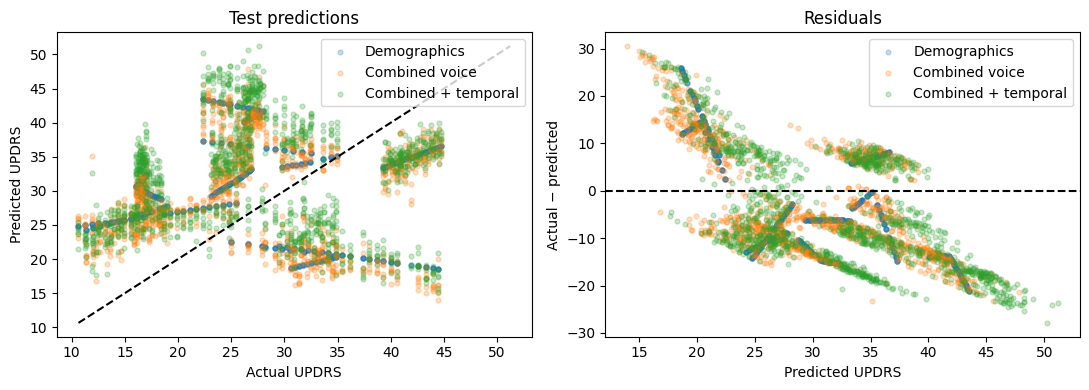

,patient,actual,demographics,combined,temporal
575,5,40.910,34.365,35.266,34.134
1198,9,23.096,29.301,30.127,32.500
1855,14,10.646,24.787,25.408,24.025
2671,20,18.362,28.756,28.673,31.150
3478,26,30.660,18.719,20.859,23.294
3608,27,11.345,24.225,19.533,22.202
4039,30,44.469,18.593,16.269,17.319
4165,31,29.818,33.438,35.592,38.351
5418,40,26.170,40.049,42.978,43.749


In [27]:
# Compare predictions and residuals for all three models.
errors = pd.DataFrame({
    "patient": groups_test, "actual": y_test,
    "demographics": predictions["Linear / demographics"],
    "combined": predictions["Linear / combined"],
    "temporal": predictions["Linear / temporal"],
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, label in [("demographics", "Demographics"), ("combined", "Combined voice"),
                    ("temporal", "Combined + temporal")]:
    errors[name + "_residual"] = errors["actual"] - errors[name]
    errors[name + "_error"] = errors[name + "_residual"].abs()
    axes[0].scatter(errors["actual"], errors[name], alpha=0.25, s=12, label=label)
    axes[1].scatter(errors[name], errors[name + "_residual"], alpha=0.25, s=12, label=label)

values = errors[["actual", "demographics", "combined", "temporal"]]
limits = [values.min().min(), values.max().max()]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Actual UPDRS", ylabel="Predicted UPDRS", title="Test predictions")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted UPDRS", ylabel="Actual − predicted", title="Residuals")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

display(errors.groupby("patient").head(1)[
    ["patient", "actual", "demographics", "combined", "temporal"]
].round(3))

Adding voice features, including changes over time, did not fix the large prediction errors. The temporal model brought some predictions closer to the actual scores but pushed others farther away. All three models still repeatedly overpredicted some groups of recordings and underpredicted others. This suggests the errors are systematic, which we examine next by comparing errors for each patient.

,recordings,demographics_MAE,combined_MAE,temporal_MAE,baseline_MAE,demographics_bias,combined_bias,temporal_bias
patient,,,,,,,,
5,156,6.935,7.176,6.511,13.738,6.935,7.176,6.511
9,152,6.188,8.109,10.156,3.039,-6.188,-8.109,-10.156
14,136,8.489,8.263,7.017,10.099,-8.489,-8.263,-6.933
20,134,13.612,12.269,16.522,11.185,-13.612,-12.269,-16.522
26,130,10.926,10.482,6.099,3.669,10.926,10.422,5.617
27,129,10.646,8.412,10.237,12.682,-10.646,-8.412,-10.237
30,126,16.643,17.370,16.441,8.787,16.643,17.370,16.441
31,130,5.871,7.015,10.074,3.444,-5.871,-6.957,-10.074
40,142,15.854,15.418,19.264,2.162,-15.854,-15.418,-19.264


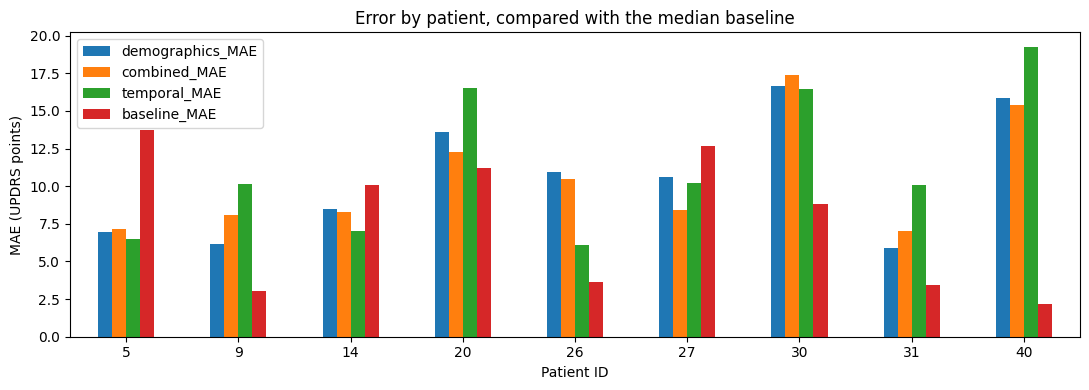

demographics — equal-patient MAE: 10.574 — patients beating baseline: 3
combined — equal-patient MAE: 10.502 — patients beating baseline: 3
temporal — equal-patient MAE: 11.369 — patients beating baseline: 3
Patients helped by adding voice features: 5
Patients helped by adding temporal features: 4


In [28]:
# Check whether voice features help the same patients or only a few.
baseline_name = comparison.loc[["Mean baseline", "Median baseline"], "CV MAE"].idxmin()
errors["baseline_error"] = np.abs(errors["actual"] - predictions[baseline_name])
patient_errors = errors.groupby("patient").agg(
    recordings=("actual", "size"),
    demographics_MAE=("demographics_error", "mean"),
    combined_MAE=("combined_error", "mean"), temporal_MAE=("temporal_error", "mean"),
    baseline_MAE=("baseline_error", "mean"),
    demographics_bias=("demographics_residual", "mean"),
    combined_bias=("combined_residual", "mean"),
    temporal_bias=("temporal_residual", "mean"),
)
display(patient_errors.round(3))
patient_errors[["demographics_MAE", "combined_MAE", "temporal_MAE", "baseline_MAE"]].plot.bar(figsize=(11, 4))
plt.xlabel("Patient ID")
plt.ylabel("MAE (UPDRS points)")
plt.title(f"Error by patient, compared with the {baseline_name.lower()}")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

for name in ["demographics", "combined", "temporal"]:
    print(name, "— equal-patient MAE:", round(patient_errors[name + "_MAE"].mean(), 3),
          "— patients beating baseline:", int((patient_errors[name + "_MAE"] < patient_errors["baseline_MAE"]).sum()))
print("Patients helped by adding voice features:",
      int((patient_errors["combined_MAE"] < patient_errors["demographics_MAE"]).sum()))
print("Patients helped by adding temporal features:",
      int((patient_errors["temporal_MAE"] < patient_errors["combined_MAE"]).sum()))


We compare errors within each patient to check whether adding voice features helps broadly or only for a few people. The median baseline is used because it had the better validation MAE. Equal-patient MAE gives each patient the same weight instead of weighting each recording equally.

Adding temporal features helped 4 of 9 patients compared with the combined model, but made predictions worse for the other five. Patient 26's MAE fell from 10.482 to 6.099, while patient 20's rose from 12.269 to 16.522. Giving each patient equal weight, MAE increased from 10.502 to 11.369. The worse overall result was therefore not just caused by patients with more recordings. All three models beat the median baseline for the same three patients.

In [29]:
# Check where in the score range each model makes larger errors.
score_ranges = pd.cut(
    errors["actual"], bins=[-np.inf, 20, 30, 40, np.inf],
    labels=["Below 20", "20 to <30", "30 to <40", "40 or above"], right=False,
)
range_errors = errors.groupby(score_ranges.rename("Actual score"), observed=True).agg(
    recordings=("actual", "size"), patients=("patient", "nunique"),
    demographics_MAE=("demographics_error", "mean"),
    combined_MAE=("combined_error", "mean"), temporal_MAE=("temporal_error", "mean"),
    baseline_MAE=("baseline_error", "mean"),
    demographics_bias=("demographics_residual", "mean"),
    combined_bias=("combined_residual", "mean"),
    temporal_bias=("temporal_residual", "mean"),
)
display(range_errors.round(3))

,recordings,patients,demographics_MAE,combined_MAE,temporal_MAE,baseline_MAE,demographics_bias,combined_bias,temporal_bias
Actual score,,,,,,,,,
Below 20,346,3,11.853,10.491,12.481,12.234,-11.853,-10.491,-12.481
20 to <30,441,6,9.622,10.270,12.209,2.821,-8.493,-9.117,-11.706
30 to <40,277,4,9.792,10.044,8.829,5.591,8.266,8.006,5.133
40 or above,171,2,10.815,11.207,10.583,14.191,10.815,11.207,10.583


We grouped recordings by actual UPDRS score to see where each model struggled. The combined voice features helped compared with demographics alone below 20, but not in the other ranges. Adding temporal features helped compared with the combined model in both ranges at or above 30, but increased error in both ranges below 30. Those lower ranges contain 787 of the 1,235 recordings, helping explain why overall error increased.

All three models still tended to predict low scores too high and high scores too low, and all lost to the median baseline between 20 and 40. Each range contains only a few patients, and a patient can appear in more than one range. These patterns could reflect differences between patients as well as differences in score.

### What we learned

Taking the log made the features less skewed, but it did not improve linear regression on its own: CV MAE increased from 9.336 to 9.429. Combining the logged Jitter and Shimmer measurements helped, bringing MAE down to 9.065. However, using only age, sex, and recording time still performed best at 8.728. The nonlinear models did not improve on that result.

We also tested whether changes from a patient’s earliest recording session were more useful than the voice measurements alone. Adding these features increased validation MAE from 9.065 to 9.142 and test MAE from 10.411 to 11.302. They helped some patients, but did not improve predictions overall in this linear model.

On the test patients, the combined voice features barely changed the overall error compared with demographics alone, while adding temporal features made it worse. All three models performed worse than simply predicting the training mean or median. For the models we tested, the voice measurements did not add much useful information for predicting new patients.

We may simply need data from more patients. Although we had thousands of recordings, they came from only 33 training patients. The models may have picked up differences between those people’s voices rather than patterns that predict UPDRS for new patients. Adding more patients, rather than just more recordings of the same people, would help us check whether that was the problem.